# Week 2 – Assignment 01: A Tiny Network, by Hand

## 1. Introduction

A neural network is a computational model inspired by the human brain. It learns patterns from data by adjusting weights and biases during training.

In this assignment, we will build a simple neural network from scratch using Python and NumPy, without using deep learning frameworks such as TensorFlow or PyTorch.

## 2. Objectives

- Understand neurons, weights, biases, and activation functions.
- Implement forward propagation.
- Calculate Mean Squared Error (MSE) loss.
- Implement backpropagation manually.
- Train a neural network using the XOR dataset.
- Visualize the training loss using a graph.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Libraries imported successfully!")

NumPy version: 2.4.6
Libraries imported successfully!


## 3. Implementing a Single Neuron

A neuron is the basic processing unit of a neural network. It receives input values, multiplies them by weights, adds a bias, and applies an activation function.

The mathematical representation is:

**Weighted Sum:**

z = (input × weight) + bias

**Sigmoid Activation:**

σ(z) = 1 / (1 + e⁻ᶻ)

The sigmoid function converts the result into a value between 0 and 1.

In [2]:


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


inputs = np.array([1.0, 0.5])

weights = np.array([0.4, -0.2])
bias = 0.1

weighted_sum = np.dot(inputs, weights) + bias


output = sigmoid(weighted_sum)

print("Input values:", inputs)
print("Weights:", weights)
print("Bias:", bias)
print("Weighted sum:", weighted_sum)
print("Neuron output:", output)

Input values: [1.  0.5]
Weights: [ 0.4 -0.2]
Bias: 0.1
Weighted sum: 0.4
Neuron output: 0.598687660112452


# Single Neuron Implementation

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Input values
inputs = np.array([1.0, 0.5])

# Weights and bias
weights = np.array([0.4, -0.2])
bias = 0.1

# Calculate weighted sum
weighted_sum = np.dot(inputs, weights) + bias

# Apply sigmoid activation
output = sigmoid(weighted_sum)

print("Input values:", inputs)
print("Weights:", weights)
print("Bias:", bias)
print("Weighted sum:", weighted_sum)
print("Neuron output:", output)

In [3]:
# XOR Dataset

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y = np.array([
    [0],
    [1],
    [1],
    [0]
], dtype=float)

print("Input data:")
print(X)

print("\nExpected output:")
print(y)

Input data:
[[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]

Expected output:
[[0.]
 [1.]
 [1.]
 [0.]]


In [4]:
# Initialize the neural network parameters

rng = np.random.default_rng(42)

W1 = rng.normal(0, 1, (2, 3))
b1 = np.zeros((1, 3))

W2 = rng.normal(0, 1, (3, 1))
b2 = np.zeros((1, 1))

learning_rate = 0.5

print("Input-to-hidden weights:\n", W1)
print("\nHidden layer bias:\n", b1)
print("\nHidden-to-output weights:\n", W2)
print("\nOutput layer bias:\n", b2)

Input-to-hidden weights:
 [[ 0.30471708 -1.03998411  0.7504512 ]
 [ 0.94056472 -1.95103519 -1.30217951]]

Hidden layer bias:
 [[0. 0. 0.]]

Hidden-to-output weights:
 [[ 0.1278404 ]
 [-0.31624259]
 [-0.01680116]]

Output layer bias:
 [[0.]]


## 5. Forward Propagation

Forward propagation is the process of passing input data through the neural network to generate an output prediction.

The hidden layer calculates:

**H = sigmoid(X × W1 + b1)**

The output layer calculates:

**Output = sigmoid(H × W2 + b2)**

Here, H represents the activated output of the hidden layer.

In [5]:
# Forward Propagation

def forward_propagation(X, W1, b1, W2, b2):
    # Hidden layer
    hidden = sigmoid(np.dot(X, W1) + b1)

    # Output layer
    output = sigmoid(np.dot(hidden, W2) + b2)

    return hidden, output


# Test forward propagation
hidden, predictions = forward_propagation(X, W1, b1, W2, b2)

print("Hidden layer output:")
print(hidden)

print("\nNetwork predictions:")
print(predictions)

Hidden layer output:
[[0.5        0.5        0.5       ]
 [0.71921371 0.12444053 0.21379844]
 [0.57559524 0.26115306 0.679277  ]
 [0.77648205 0.04783324 0.36546352]]

Network predictions:
[[0.47437206]
 [0.51224733]
 [0.49489617]
 [0.51948978]]


In [6]:
# Mean Squared Error Loss Function

def calculate_loss(actual, predicted):
    loss = np.mean((actual - predicted) ** 2)
    return loss


# Calculate initial loss
initial_loss = calculate_loss(y, predictions)

print("Initial Mean Squared Error:", initial_loss)

Initial Mean Squared Error: 0.24698275910535605


## 7. Backpropagation and Gradient Descent

Backpropagation is the process of calculating how much each weight and bias contributes to the network's prediction error.

The gradients are calculated by moving backward from the output layer to the hidden layer.

Gradient descent updates the weights and biases in the opposite direction of their gradients to reduce the loss.

The sigmoid derivative is:

**sigmoid'(x) = sigmoid(x) × (1 − sigmoid(x))**

In [7]:
# Sigmoid Derivative

def sigmoid_derivative(output):
    return output * (1 - output)


# Backpropagation and Gradient Descent

def backward_propagation(X, y, hidden, output,
                         W1, b1, W2, b2, learning_rate):

    # Output layer gradient
    d_output = (2 / y.size) * (output - y) * sigmoid_derivative(output)

    # Hidden layer gradient
    d_hidden = (d_output @ W2.T) * sigmoid_derivative(hidden)

    # Calculate gradients for weights and biases
    dW2 = hidden.T @ d_output
    db2 = np.sum(d_output, axis=0, keepdims=True)

    dW1 = X.T @ d_hidden
    db1 = np.sum(d_hidden, axis=0, keepdims=True)

    # Update weights and biases
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    return W1, b1, W2, b2


print("Backpropagation function defined successfully!")

Backpropagation function defined successfully!


## 8. Training the Neural Network

Training is the process of repeatedly passing input data through the network, calculating the prediction error, and updating weights and biases.

In this assignment, the network will be trained using the XOR dataset for 10,000 iterations.

The learning rate controls how much the weights are adjusted during each update.

In [8]:
# Train the Neural Network

epochs = 10000
loss_history = []

for step in range(epochs):

    # Forward propagation
    hidden, predictions = forward_propagation(
        X, W1, b1, W2, b2
    )

    # Calculate loss
    loss = calculate_loss(y, predictions)
    loss_history.append(loss)

    # Backpropagation and weight updates
    W1, b1, W2, b2 = backward_propagation(
        X, y, hidden, predictions,
        W1, b1, W2, b2, learning_rate
    )

    # Display loss every 2000 iterations
    if step % 2000 == 0:
        print(f"Iteration {step}: Loss = {loss:.6f}")

print("\nTraining completed!")

Iteration 0: Loss = 0.246983
Iteration 2000: Loss = 0.013934
Iteration 4000: Loss = 0.002968
Iteration 6000: Loss = 0.001515
Iteration 8000: Loss = 0.000994

Training completed!


## 9. Loss Curve Visualization

A loss curve is a graph that shows how the network's error changes during training.

The X-axis represents the number of training iterations, while the Y-axis represents the Mean Squared Error.

A decreasing loss curve indicates that the network is learning and improving its predictions.

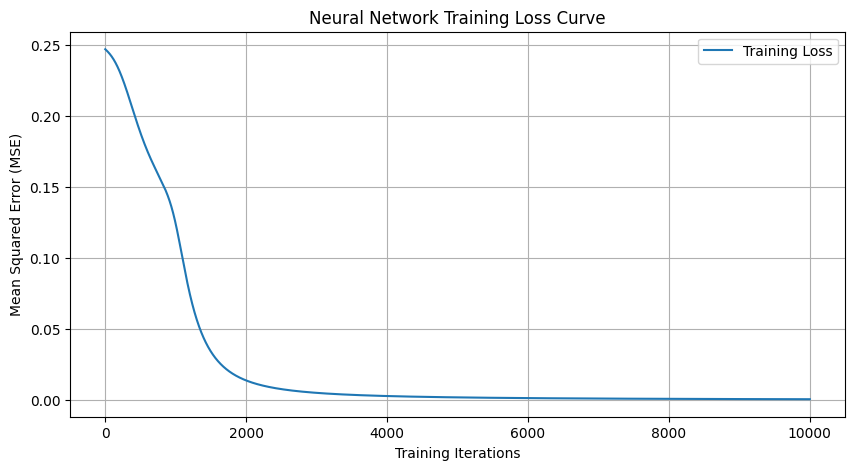

In [9]:
# Plot the Training Loss Curve

plt.figure(figsize=(10, 5))

plt.plot(loss_history, label="Training Loss")

plt.title("Neural Network Training Loss Curve")
plt.xlabel("Training Iterations")
plt.ylabel("Mean Squared Error (MSE)")

plt.legend()
plt.grid(True)
plt.show()

# Step 10: Test the Trained Neural Network

hidden, final_predictions = forward_propagation(
    X, W1, b1, W2, b2
)

rounded_predictions = np.round(final_predictions)

print("Input | Actual Output | Predicted Output")
print("-----------------------------------------")

for i in range(len(X)):
    print(
        f"{X[i]} |      {int(y[i][0])}       |"
        f"        {int(rounded_predictions[i][0])}"
    )

print("\nFinal MSE Loss:", calculate_loss(y, final_predictions))

In [13]:
# Test the trained neural network

hidden, final_predictions = forward_propagation(
    X, W1, b1, W2, b2
)

rounded_predictions = np.round(final_predictions)

print("Input | Actual Output | Predicted Output")
print("-----------------------------------------")

for i in range(len(X)):
    print(
        f"{X[i]} |      {int(y[i][0])}       |"
        f"        {int(rounded_predictions[i][0])}"
    )

print("\nFinal MSE Loss:", calculate_loss(y, final_predictions))

Input | Actual Output | Predicted Output
-----------------------------------------
[0. 0.] |      0       |        0
[0. 1.] |      1       |        1
[1. 0.] |      1       |        1
[1. 1.] |      0       |        0

Final MSE Loss: 0.0007328099800830122


## 11. Understanding Backpropagation – Five Sentences

1. Backpropagation helps a neural network learn from its prediction errors.
2. First, the network compares its predicted output with the actual output.
3. It calculates how much each weight and bias contributes to the error.
4. The network sends this error information backward through its layers.
5. Finally, gradient descent adjusts the weights and biases to reduce future errors.